In [ ]:
# Install CloudDrift
!pip install -q "zarr<3" "xarray==2025.1.2" clouddrift

# Install Cartopy
!pip install -q cartopy

In [ ]:
# ==========================================
# IMPORTING LIBRARIES AND LOADING DATASET
# ==========================================

import clouddrift as cd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import shapely.geometry as sgeom
import matplotlib.patheffects as pe
import matplotlib.patches as patches

from clouddrift.datasets import gdp6h
from clouddrift.ragged import subset
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from matplotlib.colors import Normalize, LogNorm
from matplotlib.cm import ScalarMappable
from sklearn.model_selection import train_test_split, KFold
from shapely.prepared import prep
from shapely.ops import unary_union
from scipy.sparse import coo_matrix, csr_matrix

import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='cartopy.io')


# Load the 6 hourly Global Drifter Program dataset (xarray dataset)
ds = gdp6h()
ds

<xarray.Dataset> Size: 2GB
Dimensions:                (traj: 28706, obs: 48840300)
Coordinates:
    id                     (traj) int64 230kB ...
    time                   (obs) datetime64[ns] 391MB ...
Dimensions without coordinates: traj, obs
Data variables: (12/48)
    BuoyTypeManufacturer   (traj) <U20 2MB ...
    BuoyTypeSensorArray    (traj) <U20 2MB ...
    CurrentProgram         (traj) float64 230kB ...
    DeployingCountry       (traj) <U20 2MB ...
    DeployingShip          (traj) <U20 2MB ...
    DeploymentComments     (traj) <U20 2MB ...
    ...                     ...
    start_lon              (traj) float32 115kB ...
    temp                   (obs) float32 195MB ...
    typebuoy               (traj) |S10 287kB ...
    typedeath              (traj) int8 29kB ...
    ve                     (obs) float32 195MB ...
    vn                     (obs) float32 195MB ...
Attributes: (12/18)
    Conventions:          CF-1.6
    acknowledgement:      Lumpkin, Rick; Centurioni, Luca (2019). NOAA Global...
    contributor_name:     NOAA Global Drifter Program
    contributor_role:     Data Acquisition Center
    date_created:         2025-07-14T15:15:03.441003
    doi:                  10.25921/7ntx-z961
    ...                   ...
    publisher_name:       GDP Drifter DAC
    publisher_url:        https://www.aoml.noaa.gov/phod/gdp
    summary:              Global Drifter Program six-hourly data
    time_coverage_end:    2025-01-20:00:00:00Z
    time_coverage_start:  1979-02-15:00:00:00Z
    title:                Global Drifter Program drifting buoy collection

In [ ]:
# LAT and LON of full North Atlantic Ocean Basin
LAT_MIN, LAT_MAX = 10.0, 45.0
LON_MIN, LON_MAX = -80.0, -20.0
region_name = "North Atlantic Ocean Basin"

In [ ]:
# ==========================================
# DATA WRANGLING
# ==========================================

# ------------------------------------------------------------------
# Get observations within our region
# ------------------------------------------------------------------

# Extract lats and lons
lats = ds['lat'].values
lons = ((ds['lon'].values + 180) % 360) - 180

# Get observation within required region
mask = ((lats >= LAT_MIN) & (lats < LAT_MAX) &
       (lons >= LON_MIN) & (lons < LON_MAX))

# ------------------------------------------------------------------
# Give every observation its drifter id (id and rowsize are per trajectory)
# ------------------------------------------------------------------

# Duplicates each ID by its corresponding 'rowsize' count
obs_ids = np.repeat(ds['id'].values, ds['rowsize'].values)
assert len(obs_ids) == ds.sizes['obs'], "rowsize does not add up to the number of observations"

# ------------------------------------------------------------------
# Filter the data and build the dataframe
# ------------------------------------------------------------------

# Slice the arrays using the boolean mask to filter all 8 core variables
filtered_lats = lats[mask]
filtered_lons = lons[mask]
filtered_ids = obs_ids[mask]
filtered_times = ds['time'].values[mask]
filtered_ve = ds['ve'].values[mask]
filtered_vn = ds['vn'].values[mask]
filtered_temp = ds['temp'].values[mask]
filtered_drogue = ds['drogue_status'].values[mask]

# Build the DataFrame
df = pd.DataFrame({
    'id': filtered_ids,
    'time': filtered_times,
    'lat': filtered_lats,
    'lon': filtered_lons,
    've': filtered_ve,
    'vn': filtered_vn,
    'temp': filtered_temp,
    'drogue_status': filtered_drogue
})

# Sorting by id and then by time (using stable sort)
df = df.sort_values(by=['id', 'time'], kind='stable').reset_index(drop=True)

# ------------------------------------------------------------------
# Observation count and timespan
# ------------------------------------------------------------------
print(f"Number of Observations: {len(df):,}")
print(f"Number of drifters: {df['id'].nunique():,}")
print(f"{df['time'].min():%Y-%m-%d} to {df['time'].max():%Y-%m-%d}")

Number of Observations: 6,116,067
Number of drifters: 3,896
1989-10-31 to 2025-01-20


In [ ]:
# ==========================================
# DATA SUMMARY OF OUR REGION
# ==========================================

total_rows = len(df)
print(f"--- DATA SUMMARY (Total Observations: {total_rows:,}) ---\n")

missing_summary = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Valid Count': df.notna().sum(),
    'Missing (%)': (df.isna().mean() * 100).round(2),
    'Data Type': df.dtypes
}).sort_values(by='Missing Count', ascending=False)

print(missing_summary)
print("-" * 70)

# Calculate rows with complete data versus rows with at least one missing value
complete_rows = df.dropna().shape[0]
incomplete_rows = total_rows - complete_rows

print(f"Complete Rows:      {complete_rows:,} ({complete_rows / total_rows:.2%})")
print(f"Incomplete Rows:    {incomplete_rows:,} ({incomplete_rows / total_rows:.2%})")
print("=" * 70 + "\n")

--- DATA SUMMARY (Total Observations: 6,116,067) ---

               Missing Count  Valid Count  Missing (%)       Data Type
temp                  398708      5717359         6.52         float32
ve                      6149      6109918         0.10         float32
vn                      6149      6109918         0.10         float32
id                         0      6116067         0.00           int64
lon                        0      6116067         0.00         float64
lat                        0      6116067         0.00         float64
time                       0      6116067         0.00  datetime64[ns]
drogue_status              0      6116067         0.00            bool
----------------------------------------------------------------------
Complete Rows:      5,712,403 (93.40%)
Incomplete Rows:    403,664 (6.60%)



In [ ]:
# ==================================================================
# 5-FOLD CROSS-VALIDATION SPLITTER SETUP
# ==================================================================

# Set random seed for reproducibility
SEED = 42
K = 5

# ------------------------------------------------------------------
# Split unique drifter IDs into 80% train and 20% test sets
# ------------------------------------------------------------------
all_ids = df['id'].unique()  # Get all drifter identification numbers
kf = KFold(n_splits=K, shuffle=True, random_state=SEED)

print(f"Total unique drifters across dataset: {len(all_ids):,}")
print(f"Ready to run {K}-Fold Cross-Validation loop.")

Total unique drifters across dataset: 3,896
Ready to run 5-Fold Cross-Validation loop.


In [ ]:
# ==================================================================
# SPATIAL GRID CONFIGURATION
# ==================================================================
RES = 0.1

N_LAT = int(round((LAT_MAX - LAT_MIN) / RES))
N_LON = int(round((LON_MAX - LON_MIN) / RES))
N_CELLS = N_LAT * N_LON
N_STATES = N_CELLS

In [ ]:
# ==================================================================
# HELPER FUNCTIONS FOR SPATIAL GRID MAPPING & MARKOV CHAIN
# ==================================================================

# Convert latitudes and longtitudes to the states of markov chain (each cell is a state)
# Every grid is represented by the centre point
def to_state(lat, lon):
    """
    Maps geographic (latitude, longitude) coordinates to a discrete state index.

    Coordinate System:
        - Origin: North-West corner (LAT_MAX, LON_MIN) = State 0.
        - Rows count increases downward (southward).
        - Columns count increases rightward (eastward).

    Parameters:
        lat (array-like): Latitude coordinates to convert.
        lon (array-like): Longitude coordinates to convert.

    Returns:
        1D array of integer state indices in the range [0, N_STATES).
    """
    lat_idx = np.floor((LAT_MAX - np.asarray(lat)) / RES).astype(np.int64)
    lon_idx = np.floor((np.asarray(lon) - LON_MIN) / RES).astype(np.int64)
    lat_idx = np.clip(lat_idx, 0, N_LAT - 1)
    lon_idx = np.clip(lon_idx, 0, N_LON - 1)
    return lat_idx * N_LON + lon_idx

# The inverse function of the above - converts cells into latitudes and longtitudes
def state_to_latlon(state):
    """
    Converts a 1D state index back to the geographic center (latitude, longitude)
    of its corresponding grid cell.

    Coordinate System:
        - Origin: North-West corner (LAT_MAX, LON_MIN) = State 0.
        - Rows count increases downward (southward).
        - Columns count increases rightward (eastward).

    Parameters:
        state (array-like): 1D state index or array of indices in the range [0, N_STATES).

    Returns:
        latitude, longitude coordinates representing the centers of the cells.
    """
    state = np.asarray(state)
    lat = LAT_MAX - (state // N_LON + 0.5) * RES
    lon = LON_MIN + (state % N_LON + 0.5) * RES
    return lat, lon

def count_transitions(train_df):
    """
    Constructs a sparse transition count matrix mapping drifter movements
    between grid cells over consecutive 6-hour intervals.

    Parameters:
        train_df: Training dataframe containing drifter observations.

    Returns:
        csr_matrix: Sparse matrix of raw transition counts from source to destination cells.
    """
    d = train_df[['id', 'time', 'lat', 'lon']].dropna()
    d = d.sort_values(['id', 'time'], kind='stable')

    state = to_state(d['lat'].values, d['lon'].values)
    ids = d['id'].values
    times = d['time'].values

    # Check if consecutive observations are of the same drifter and are exactly 6 hours apart
    same_drifter = (ids[1:] == ids[:-1])
    is_six_hours = (times[1:] - times[:-1]) == np.timedelta64(6, 'h')
    valid = same_drifter & is_six_hours

    src = state[:-1][valid]
    dst = state[1:][valid]

    # Create an array of 1.0 floats, with one '1' for every valid transition
    transition_values = np.ones(len(src))
    # Build a Coordinate (COO) format sparse matrix
    coo_matrix_raw = coo_matrix(
    (transition_values, (src, dst)),
    shape=(N_STATES, N_STATES)
    )
    # Convert it to Compressed Sparse Row (CSR) format and return
    return coo_matrix_raw.tocsr()

### Geographic Location to State Index (lat, lon $\to$ state)
**Corresponding Python Function:** `to_state(lat, lon)`

$$\text{row} = \left\lfloor \frac{\text{LAT_MAX} - \text{lat}}{\Delta} \right\rfloor \qquad \text{col} = \left\lfloor \frac{\text{lon} - \text{LON_MIN}}{\Delta} \right\rfloor$$

$$\text{state} = \text{row} \times N_{lon} + \text{col}$$


**Example Calculation:** For a drifter located at $\text{lat} = 24.50^\circ, \text{lon} = -65.00^\circ$:
* **Row Index:** $\lfloor (45 - 24.50) / 0.1 \rfloor = \lfloor 205.0 \rfloor \to$ **205**
* **Column Index:** $\lfloor (-65.00 - (-80)) / 0.1 \rfloor = \lfloor 150.0 \rfloor \to$ **150**
* **Final State Index:** $205 \times 600 + 150 =$ **123,150**

<br>
<hr style="border: none; border-top: 1px solid #e1e4e8; margin: 15px 0;">
<br>

### State Index to Geographic Location (state $\to$ cell centre)
**Corresponding Python Function:** `state_to_latlon(state)`

To reverse the mapping and find the geographic center point of any discrete state cell:

$$\text{row} = \left\lfloor \frac{\text{state}}{N_{lon}} \right\rfloor \qquad \text{col} = \text{state} \bmod N_{lon}$$

$$\text{lat}_c = \text{LAT_MAX} - (\text{row} + 0.5) \times \Delta \qquad \text{lon}_c = \text{LON_MIN} + (\text{col} + 0.5) \times \Delta$$

**Example Calculation:** For state index = **123,150**:
* **Row Index:** $123,150 \text{ // } 600 =$ **205**
* **Column Index:** $123,150 \bmod 600 =$ **150**
* **Latitude Center:** $45 - (205 + 0.5) \times 0.1 =$ **$24.45^\circ\text{N}$**
* **Longitude Center:** $-80 + (150 + 0.5) \times 0.1 =$ **$-64.95^\circ\text{E}$**

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)



               RUNNING FOLD 1 OF 5
Grid: 350 latitude cells x 600 longitude cells = 210,000 cells in total
Observations counted (Fold 1 Training): 4,982,840
Cells with at least one observation: 193,531 (92.2%)
Cells with NO observation (Total):   16,469 (7.8%)
Cells with NO observation (Ocean):   12,134 (5.9% of total ocean cells)
Observations per non-empty cell: median 23, max 458



/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


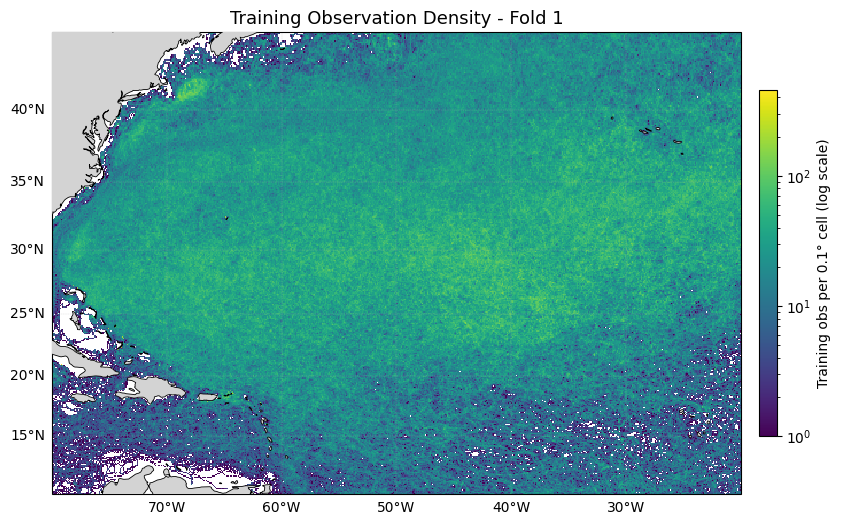


--- Fold 1 Markov Matrix Stats ---
Total raw transitions counted: 4,977,171
Pooled matrix shape: (210000, 210000)
Source cells visited: 193,467 / 210,000 (92.1%)
Non-zero entries: 1,232,085


               RUNNING FOLD 2 OF 5
Grid: 350 latitude cells x 600 longitude cells = 210,000 cells in total
Observations counted (Fold 2 Training): 4,824,114
Cells with at least one observation: 193,877 (92.3%)
Cells with NO observation (Total):   16,123 (7.7%)
Cells with NO observation (Ocean):   11,996 (5.8% of total ocean cells)
Observations per non-empty cell: median 23, max 458



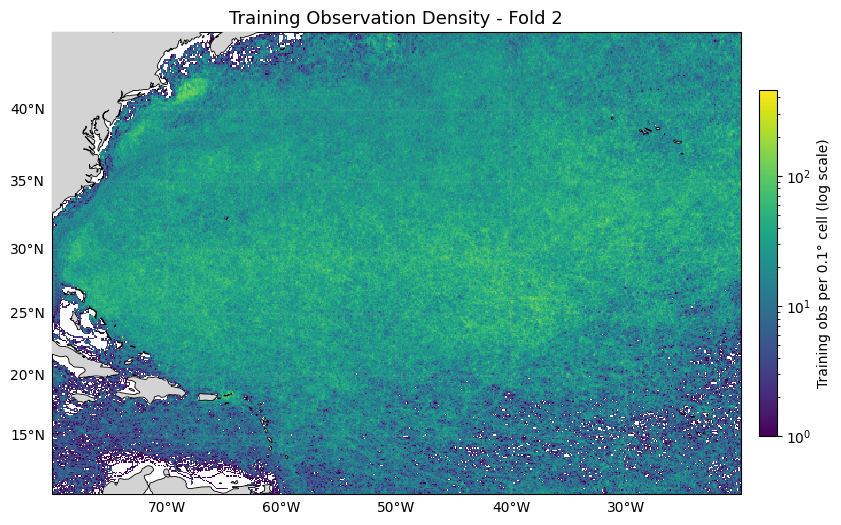


--- Fold 2 Markov Matrix Stats ---
Total raw transitions counted: 4,818,365
Pooled matrix shape: (210000, 210000)
Source cells visited: 193,830 / 210,000 (92.3%)
Non-zero entries: 1,229,441


               RUNNING FOLD 3 OF 5
Grid: 350 latitude cells x 600 longitude cells = 210,000 cells in total
Observations counted (Fold 3 Training): 4,904,746
Cells with at least one observation: 193,584 (92.2%)
Cells with NO observation (Total):   16,416 (7.8%)
Cells with NO observation (Ocean):   12,213 (5.9% of total ocean cells)
Observations per non-empty cell: median 23, max 458



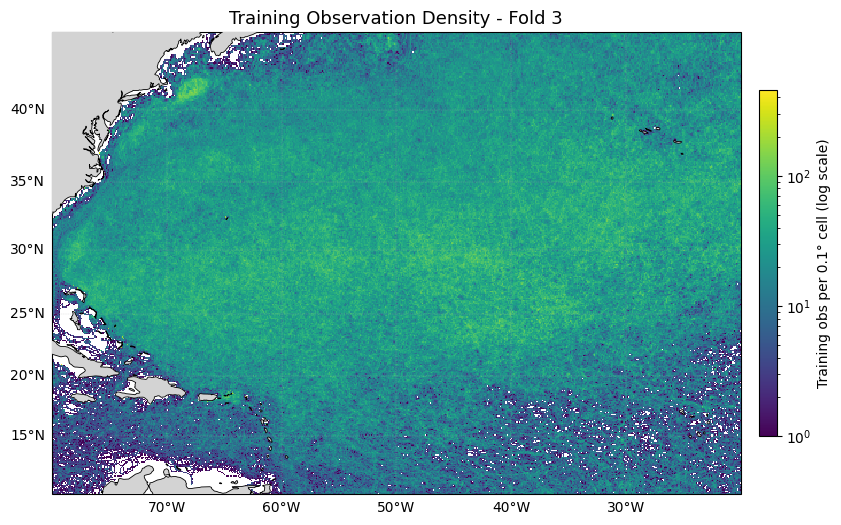


--- Fold 3 Markov Matrix Stats ---
Total raw transitions counted: 4,898,975
Pooled matrix shape: (210000, 210000)
Source cells visited: 193,524 / 210,000 (92.2%)
Non-zero entries: 1,232,986


               RUNNING FOLD 4 OF 5
Grid: 350 latitude cells x 600 longitude cells = 210,000 cells in total
Observations counted (Fold 4 Training): 4,851,922
Cells with at least one observation: 193,001 (91.9%)
Cells with NO observation (Total):   16,999 (8.1%)
Cells with NO observation (Ocean):   12,631 (6.1% of total ocean cells)
Observations per non-empty cell: median 23, max 337



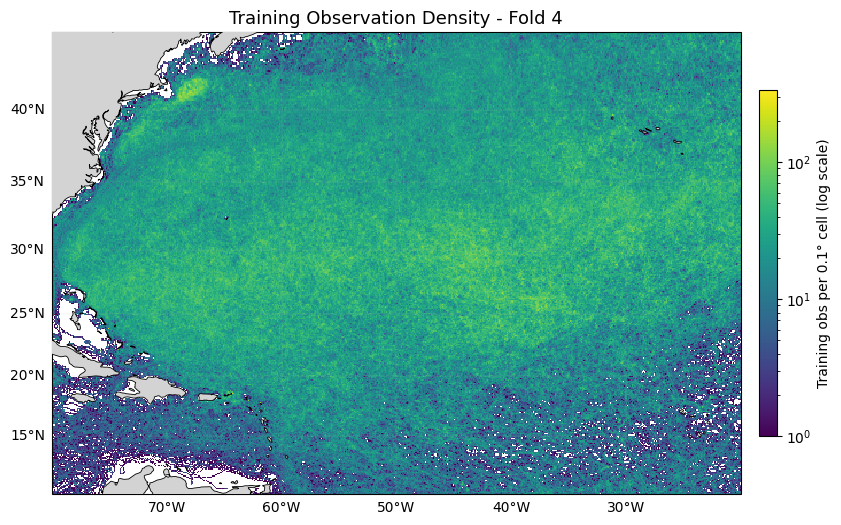


--- Fold 4 Markov Matrix Stats ---
Total raw transitions counted: 4,846,238
Pooled matrix shape: (210000, 210000)
Source cells visited: 192,939 / 210,000 (91.9%)
Non-zero entries: 1,223,655


               RUNNING FOLD 5 OF 5
Grid: 350 latitude cells x 600 longitude cells = 210,000 cells in total
Observations counted (Fold 5 Training): 4,900,646
Cells with at least one observation: 193,567 (92.2%)
Cells with NO observation (Total):   16,433 (7.8%)
Cells with NO observation (Ocean):   12,327 (6.0% of total ocean cells)
Observations per non-empty cell: median 23, max 458



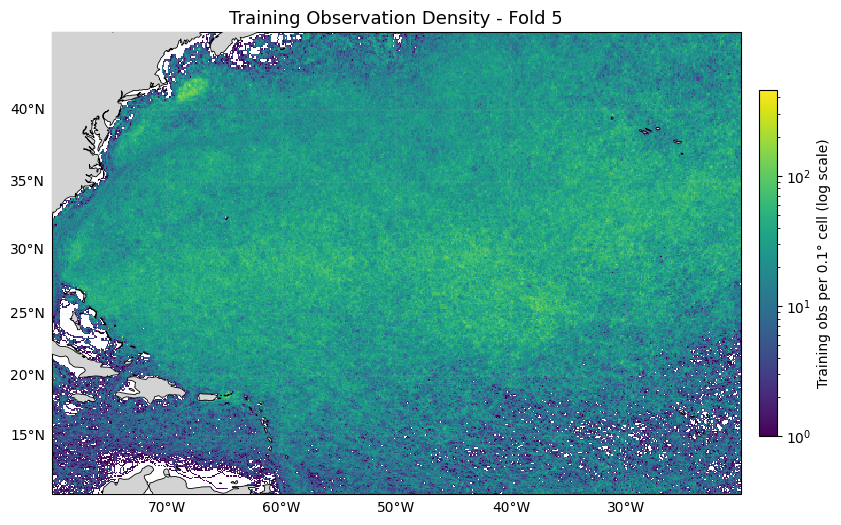


--- Fold 5 Markov Matrix Stats ---
Total raw transitions counted: 4,894,979
Pooled matrix shape: (210000, 210000)
Source cells visited: 193,519 / 210,000 (92.2%)
Non-zero entries: 1,230,721



In [ ]:
# ==================================================================
# 5-FOLD CROSS-VALIDATION: OBSERVATION DENSITY & MARKOV TRANSITION MATRIX
# ==================================================================

# Pre-compute land mask once outside the loop for efficiency
land_geom = unary_union(list(cfeature.LAND.geometries()))
prepared_land = prep(land_geom)

# Storage lists if you want to inspect results across folds later
cv_results = []

# ------------------------------------------------------------------
# Run the K-Fold Loop
# ------------------------------------------------------------------
for fold, (train_idx, test_idx) in enumerate(kf.split(all_ids), start=1):
    print(f"\n==================================================")
    print(f"               RUNNING FOLD {fold} OF {K}")
    print(f"==================================================")

    # Split data for this fold
    train_ids = all_ids[train_idx]
    test_ids = all_ids[test_idx]
    df_train = df[df['id'].isin(train_ids)].copy()
    df_test  = df[df['id'].isin(test_ids)].copy()

    # ------------------------------------------------------------------
    # PART A: OBSERVATION DENSITY PER CELL (FOR THIS FOLD'S TRAIN DATA)
    # ------------------------------------------------------------------
    data = df_train
    lat = data['lat'].to_numpy(dtype=float)
    lon = data['lon'].to_numpy(dtype=float)

    # Map continuous LAT/LONG coordinates to grid cell indices
    li = np.clip(np.floor(np.round((lat - LAT_MIN) / RES, 9)).astype(np.int64), 0, N_LAT - 1)
    lj = np.clip(np.floor(np.round((lon - LON_MIN) / RES, 9)).astype(np.int64), 0, N_LON - 1)

    # Generate a 2D matrix counting total observations per grid cell
    counts = np.bincount(li * N_LON + lj, minlength=N_CELLS).reshape(N_LAT, N_LON)

    # Identifying grid cells with zero observations
    empty_indices = np.argwhere(counts == 0)
    empty_ocean_count = 0

    # Filter empty cells to see if they are from open ocean or land
    for r, c in empty_indices:
        # Get the center LAT/LONG of this specific empty cell
        lat_center = LAT_MAX - (r + 0.5) * RES
        lon_center = LON_MIN + (c + 0.5) * RES

        # Check if the point is NOT on land
        point = sgeom.Point(lon_center, lat_center)
        if not prepared_land.contains(point):
            empty_ocean_count += 1

    # Calculate spatial coverage stats for this training fold
    empty = counts == 0
    land_cell_count = empty.sum() - empty_ocean_count
    total_ocean_cells = N_CELLS - land_cell_count
    pct_unvisited_ocean = (empty_ocean_count / total_ocean_cells) * 100

    # Print clean and comprehensive fold statistics
    print(f"Grid: {N_LAT} latitude cells x {N_LON} longitude cells = {N_CELLS:,} cells in total")
    print(f"Observations counted (Fold {fold} Training): {counts.sum():,}")
    print(f"Cells with at least one observation: {(~empty).sum():,} ({(~empty).mean():.1%})")
    print(f"Cells with NO observation (Total):   {empty.sum():,} ({empty.mean():.1%})")
    print(f"Cells with NO observation (Ocean):   {empty_ocean_count:,} ({pct_unvisited_ocean:.1f}% of total ocean cells)")
    print(f"Observations per non-empty cell: median {np.median(counts[~empty]):.0f}, max {counts.max():,}\n")

    # Display map per fold
    # Create grid-edge coordinates for each grid's LAT/LONG
    lon_e = np.linspace(LON_MIN, LON_MAX, N_LON + 1)
    lat_e = np.linspace(LAT_MIN, LAT_MAX, N_LAT + 1)

    # Sets colour scheme
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('white')
    shown = np.ma.masked_equal(counts, 0)

    # Setting geographical features and plotting figures
    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=ccrs.Mercator())
    ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=ccrs.PlateCarree())

    pm = ax.pcolormesh(
      lon_e, lat_e, shown,
      cmap=cmap,
      norm=LogNorm(vmin=1, vmax=counts.max()),
      transform=ccrs.PlateCarree(),
      zorder=1
    )

    ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=3)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=4)

    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False

    plt.colorbar(pm, ax=ax, shrink=0.75, pad=0.02, label='Training obs per 0.1° cell (log scale)')
    ax.set_title(f"Training Observation Density - Fold {fold}", fontsize=13)
    plt.show()

    # ------------------------------------------------------------------
    # PART B: MARKOV CHAIN TRANSITION MATRIX (FOR THIS FOLD)
    # ------------------------------------------------------------------
    # Count transitions across all training data in this fold
    # Returns a 2D sparse matrix of shape 210,000 * 210,000
    counts_pooled = count_transitions(df_train)

    # Row-normalise to get the single transition matrix P
    # Row_sums, inv and nz are all 1D arrays, each with one entry for each grid cell
    row_sums = np.asarray(counts_pooled.sum(axis=1)).ravel()  # Number of departures from each cell
    inv = np.zeros_like(row_sums)                             # Initialize an array of zeros
    nz = row_sums > 0                                         # True for cells with at least one departure
    inv[nz] = 1.0 / row_sums[nz]                              # For non-zero cells, set inv to 1/row_sum
    P = csr_matrix(counts_pooled.multiply(inv[:, None]))      # Form the final transition probability matrix P

    # Validation Checks & Summary of P
    visited = nz
    rs = np.asarray(P.sum(axis=1)).ravel()
    assert np.allclose(rs[visited], 1.0), f"Fold {fold}: visited rows must sum to 1"
    assert np.all(rs[~visited] == 0), f"Fold {fold}: unvisited rows should be empty"

    print(f"\n--- Fold {fold} Markov Matrix Stats ---")
    print(f"Total raw transitions counted: {int(counts_pooled.sum()):,}")
    print(f"Pooled matrix shape: {P.shape}")
    print(f"Source cells visited: {visited.sum():,} / {N_STATES:,} ({visited.mean():.1%})")
    print(f"Non-zero entries: {P.nnz:,}\n")

    # Store fold data and trained matrices for downstream evaluation
    cv_results.append({
        'fold': fold,
        'train_ids': train_ids,
        'test_ids': test_ids,
        'df_train': df_train,
        'df_test': df_test,
        'counts_pooled': counts_pooled,
        'P': P,
        'visited': visited
    })

## Understanding the transition matrix
The transition matrix `P` describes how a drifter moves from one grid cell to another in a single 6-hour step. We use 5-fold cross-validation on drifter IDs: in each round, `P` is learned only from the drifters in four folds (≈80%), capturing their movement patterns, and is then tested on the unseen drifters in the remaining fold (≈20%). Each drifter is held out exactly once, so no drifter appears in both training and testing within a round.


### Spatial Layout & Dimensions
- The North Atlantic region (10°N to 45°N, 80°W to 20°W) is divided into 0.1° × 0.1° cells, giving a 350 × 600 grid. Each cell is one **state**.
- States are numbered 0 to 209,999 depicting the location, counting west to east along each row, starting at the north-west corner
- `P` is a **210,000 × 210,000** matrix. The rows and columns are both indexed by state.

### Transition Matrix Mechanics
- Row `i` is the **starting** cell and column `j` is the **destination** cell 6 hours later.
- Entry `P[i, j]` is the probability that a drifter in cell `i` is in cell `j` after 6 hours. It is calculated as the number of times drifters moved from `i` to `j`, divided by the total number of departures from `i`.
- Each row that has data sums to 1, so it is a full probability distribution over the next cell. Rows for cells never visited by a training drifter are all zeroes.
- Only consecutive observations of the same drifter exactly 6 hours apart count as a transition.





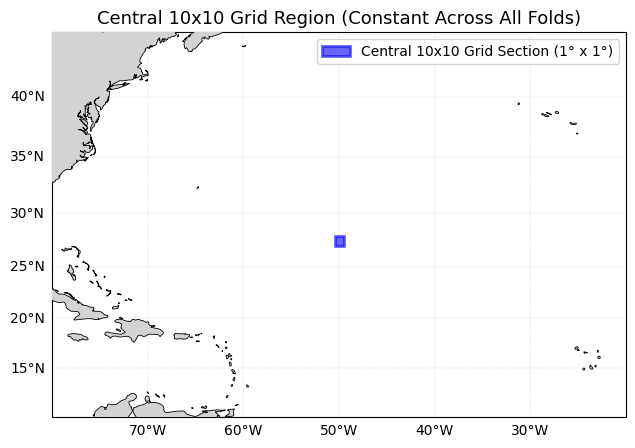

INSPECTING CENTRAL 10x10 TRANSITION SUB-MATRICES ACROSS 5 FOLDS

--- Fold 1: Outgoing Transition Probabilities from Center-Most Cell ---


,102895,102896,102897,102898,102900,102900,102901,102902,102903,102905
102895,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
103495,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
104095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
104695,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
105295,0.0,0.0,0.0,0.0,0.0263,0.0263,0.0263,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.5526,0.5526,0.1316,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.5526,0.5526,0.1316,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
108295,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0



--- Fold 2: Outgoing Transition Probabilities from Center-Most Cell ---


,102895,102896,102897,102898,102900,102900,102901,102902,102903,102905
102895,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
103495,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
104095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
104695,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
105295,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.6364,0.6364,0.0909,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.6364,0.6364,0.0909,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
108295,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0



--- Fold 3: Outgoing Transition Probabilities from Center-Most Cell ---


,102895,102896,102897,102898,102900,102900,102901,102902,102903,102905
102895,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0
103495,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0
104095,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0
104695,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0
105295,0.0,0.0,0.0,0.0,0.025,0.025,0.025,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.575,0.575,0.125,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.575,0.575,0.125,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0
108295,0.0,0.0,0.0,0.0,0.000,0.000,0.000,0.0,0.0,0.0



--- Fold 4: Outgoing Transition Probabilities from Center-Most Cell ---


,102895,102896,102897,102898,102900,102900,102901,102902,102903,102905
102895,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
103495,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
104095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
104695,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
105295,0.0,0.0,0.0,0.0,0.0435,0.0435,0.0435,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.5217,0.5217,0.0870,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.5217,0.5217,0.0870,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
108295,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0



--- Fold 5: Outgoing Transition Probabilities from Center-Most Cell ---


,102895,102896,102897,102898,102900,102900,102901,102902,102903,102905
102895,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
103495,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
104095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
104695,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
105295,0.0,0.0,0.0,0.0,0.0263,0.0263,0.0263,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.6053,0.6053,0.1316,0.0,0.0,0.0
105895,0.0,0.0,0.0,0.0,0.6053,0.6053,0.1316,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
107095,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0
108295,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0


In [ ]:
# ==================================================================
# Visualizing the Regional Map & Inspecting Central 10x10 Sub-Matrices
# ==================================================================
# Note: 10x10 grid = 1° x 1° geographic region

# ------------------------------------------------------------------
# Reference map for the central 10x10 region
# ------------------------------------------------------------------

# Find the center state of your 2D grid map
mid_row = N_LAT // 2
mid_col = N_LON // 2
center_state = mid_row * N_LON + mid_col

# Get the exact center LAT/LONG of that central cell using your function
center_lat, center_lon = state_to_latlon(center_state)

# Define the 10x10 bounds
half_span = 5 * RES   # 5 cells * 0.1° resolution = 0.5° offset from center
lat_top = center_lat + half_span
lat_bottom = center_lat - half_span
lon_left = center_lon - half_span
lon_right = center_lon + half_span

# Plot the reference map ONCE (since the region is identical for every fold)
fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=ccrs.Mercator())
ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=3)
ax.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=4)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5, linestyle='--')
gl.top_labels = gl.right_labels = False

rect = patches.Rectangle(
    (lon_left, lat_bottom),
    lon_right - lon_left,
    lat_top - lat_bottom,
    linewidth=2.0,
    edgecolor='blue',
    facecolor='blue',
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    zorder=5,
    label='Central 10x10 Grid Section (1° x 1°)'
)
ax.add_patch(rect)
ax.set_title("Central 10x10 Grid Region (Constant Across All Folds)", fontsize=13)
ax.legend(loc='upper right')
plt.show()

# ------------------------------------------------------------------
# Generating state indices for 10x10 patch
# ------------------------------------------------------------------

# Generate the 10x10 grid boundaries using numpy
lat_coords = np.linspace(lat_top - RES/2, lat_bottom + RES/2, 10)
lon_coords = np.linspace(lon_left + RES/2, lon_right - RES/2, 10)
grid_lats, grid_lons = np.meshgrid(lat_coords, lon_coords, indexing='ij')

# Convert coordinates to state indices using to_state helper function
cell_indices = to_state(grid_lats.ravel(), grid_lons.ravel())

# ------------------------------------------------------------------
# Inspecting Transition Sub-Matrix across all folds
# ------------------------------------------------------------------

print("=" * 70)
print("INSPECTING CENTRAL 10x10 TRANSITION SUB-MATRICES ACROSS 5 FOLDS")
print("=" * 70)

# Loop through 5 CV folds to inspect the Markov Chain P matrix for this exact area
for fold_data in cv_results:
    fold = fold_data['fold']
    P = fold_data['P']

    # Slice the sparse P matrix for this 10x10 block
    P_sub = P[cell_indices, :][:, cell_indices].toarray()

    print(f"\n--- Fold {fold}: Outgoing Transition Probabilities from Center-Most Cell ---")

    # CALCULATE 1D FLAT INDEX OF THE EXACT CENTER CELL WITHIN THIS 10X10 GRID
    # RESTRICTING TO OUTGOING TRANSITION PROBABILITIES FROM THAT CENTER CELL TO ALL OTHER CELLS
    center_local_idx = 5 * 10 + 5

    # Extract that single row and reshape it into a 10x10 2D array
    transition_distribution_2d = P_sub[center_local_idx, :].reshape(10, 10)

    # Reshape the 100 state IDs into a 10x10 grid to use as labels
    grid_state_ids = cell_indices.reshape(10, 10)

    # Wrap into a pandas DataFrame using the actual state IDs for rows and columns
    sub_df = pd.DataFrame(
        np.round(transition_distribution_2d, 4),
        index=grid_state_ids[:, 0],   # Use the state ID of the first column cell as the row identifier
        columns=grid_state_ids[0, :]  # Use the state IDs across the top row as column headers
    )

    display(sub_df)

In [ ]:
# ==================================================================
# TESTING ON 5-FOLD CV & MULTI-HORIZON EVALUATION
# ==================================================================

# Calculates the great-circle distance (shortest distance) between two points on the Earth (km)
def hav(lat1, lon1, lat2, lon2):
    """
    Calculates the great-circle distance between two geographic coordinate points
    on the Earth using the Haversine formula.

    Parameters:
        lat1: Latitude coordinate(s) of the starting point(s) in decimal degrees
        lon1: Longitude coordinate(s) of the starting point(s) in decimal degrees
        lat2: Latitude coordinate(s) of the destination point(s) in decimal degrees
        lon2: Longitude coordinate(s) of the destination point(s) in decimal degrees

    Returns:
        float or np.ndarray: Great-circle distance between the points in kilometers
    """
    R = 6371.0  # Earth radius in kilometers
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])  # Converts LAT/LONG degrees to radians
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2  # Applies Haversine trigonometric formula
    c = 2 * np.arcsin(np.sqrt(a))  # Computes angular distance (in radians) between points along Earth's curve
    return R * c  # R * c --> converts angular distance to physical distance



# Extracts valid trajectory pairs separated by exactly n_steps (6 hours * n_steps)
def build_pairs_xy(test_df, n_steps=12): # n = 12 --> 3 days
    """
    Finds pairs of data points from the same drifter where the starting position and ending position
    are separated by the exact time period we want to test (eg. 3, 10 or 15 days apart)

    Parameters:
        test_df: Test dataframe containing drifter ID, time, latitude, and longitude.
        n_steps (default=12): Number of 6-hour time steps between the start and end observation pairs.

    Returns:
        pd.DataFrame: A filtered dataframe containing valid pairs with drifter IDs, start/end
                      state indices, and exact starting/ending geographic coordinates.
    """
    # Drop rows with missing essential values and sort stably by drifter ID and timestamp
    d = test_df[['id', 'time', 'lat', 'lon']].dropna()
    d = d.sort_values(['id', 'time'], kind='stable')

    ids, times = d['id'].values, d['time'].values
    lat, lon = d['lat'].values, d['lon'].values

    # Map the LAT/LONG to Markov state cell indices (grid indices)
    state = to_state(lat, lon)

    # Boolean mask: verify observations belong to the exact same drifter ID
    # and are separated precisely by the target time duration (6 hours * n_steps)
    ok = ((ids[n_steps:] == ids[:-n_steps]) &
          ((times[n_steps:] - times[:-n_steps]) == np.timedelta64(6 * n_steps, 'h')))

    # Package and return valid baseline and target pairs into a structured DataFrame
    return pd.DataFrame({
        'id': ids[:-n_steps][ok],
        'start': state[:-n_steps][ok],
        'end': state[n_steps:][ok],
        'lat0': lat[:-n_steps][ok], 'lon0': lon[:-n_steps][ok],
        'lat1': lat[n_steps:][ok], 'lon1': lon[n_steps:][ok]
    })


# Generates point forecasts for where a debris patch will end up after N time steps
# using Markov chain matrix math
def forecast_points(P_mat, start_states, n_steps, chunk_size=500, prune=1e-6):
    """
    Simulates how probability spreads out over time from starting grid cells and
    predicts the final destination (Top-1 cell and Expected Mean position).

    Top-1 cell: The mode of the probability distribution
    (the single grid cell where the highest concentration of probability mass lands after N steps).

    Expected mean position: The center of mass (the probability-weighted geographic average of all cells
    where probability mass currently resides, rather than the average of past observations).

    Parameters:
        P_mat (csr_matrix): The trained Markov transition probability matrix.
        start_states (array-like): List of starting grid cell state indices to forecast from.
        n_steps (int): Number of 6-hour steps to propagate forward (e.g., 12 = 3 days, 40 = 10 days).
        chunk_size (efault=500): Number of starting states processed at once to manage computer memory.
        prune (default=1e-6): Threshold to drop tiny probability weights so the sparse math stays fast.

    Returns:
        tuple of np.ndarray: (top1, mean) coordinate arrays representing the predicted end locations.
    """
    # Precompute the geographic latitude and longitude centers for every single cell on the entire grid
    all_lat, all_lon = state_to_latlon(np.arange(N_STATES))

    # Convert the transition matrix into Compressed Sparse Row format for faster matrix multiplication
    P_csr = P_mat.tocsr()
    n = len(start_states)

    # Set up empty arrays to store our two types of predictions for every starting point
    top1 = np.empty((n, 2))
    mean = np.empty((n, 2))

    # Process the starting states in smaller batches (chunks) to avoid crashing computer memory
    for a in range(0, n, chunk_size):
        # a is the start of the current batch while b is the end of the current batch
        b = min(a + chunk_size, n)

        # V --> probability vector matrix for the current batch of 'chunk_size' start
        # shape=(b - a, N_STATES) --> creates a sparse matrix with 'chunk_size' rows and 210,000 columns
        # V has a 1.0 for the grids corresponding to the drifters' starting cell. Everywhere else is 0
        V = csr_matrix((np.ones(b - a), (np.arange(b - a), start_states[a:b])), shape=(b - a, N_STATES))

        # Step forward in time by repeatedly multiplying the probability vector by the transition matrix P
        for _ in range(n_steps):

            # Each step spreads probability mass to neighboring cells
            # (1.0s in V starts splitting into fractions and spreading out across the neighbouring ocean cells with time!)
            V = V @ P_csr

            # Remove negligible probability weights to keep the sparse matrix clean and fast
            if prune:
                V.data[V.data < prune] = 0
                V.eliminate_zeros()

        # Sum up total probability mass and find the single cell with the highest probability
        mass = np.asarray(V.sum(axis=1)).ravel()  # Total remaining probability per drifter (handling probability leakage or pruning)
        best = np.asarray(V.argmax(axis=1)).ravel()  # Grid cell index with the highest probability (Top-1 prediction)
        ok = mass > 0    # Safety check: Starting points have any probability left (False = stuck/pruned to 0)
        s_lat, s_lon = state_to_latlon(start_states[a:b]) # Fallback coordinates (original starting position)

        # Top-1 Prediction: Assign coordinates of the single most probable destination cell
        top1[a:b, 0] = np.where(ok, all_lat[best], s_lat)   # Assign Top-1 LAT (or fallback to start)
        top1[a:b, 1] = np.where(ok, all_lon[best], s_lon)   # Assign Top-1 LONG (or fallback to start)

        # Expected Mean Prediction: Compute the probability-weighted geographic center of the entire spread
        with np.errstate(invalid='ignore', divide='ignore'):
            mean[a:b, 0] = np.where(ok, (V @ all_lat) / mass, s_lat)    # Probability-weighted LAT center
            mean[a:b, 1] = np.where(ok, (V @ all_lon) / mass, s_lon)    # Probability-weighted LONG center

    # Return both sets of predicted coordinates
    return top1, mean



# Validates trained Markov models across all cross-validation folds and time horizons against unseen test data
def evaluate_cv_forecasts(cv_results, horizons=[12, 40, 60]):
    """
    Validates each fold's trained transition matrix (P) against its respective
    unseen test set (df_test) across 3-day (12 steps) and 10-day (40 steps) horizons.

    Parameters:
        cv_results (list of dict): List containing pre-trained model data, transition matrices (P),
                                   visited masks, and test dataframes for each cross-validation fold.
        horizons (default=[12, 40,60]): List of time step horizons to evaluate
                                                (e.g., 12 steps = 3 days, 40 steps = 10 days).

    Returns:
        pd.DataFrame: A summary dataframe containing evaluation metrics (MAE and Skill Score)
                      broken down by fold and forecast horizon.
    """
    summary_rows = []

    print("=" * 70)
    print("RUNNING CROSS-VALIDATION EVALUATION ACROSS FOLDS & HORIZONS")
    print("=" * 70)

    # Loop through each cross-validation fold to test the model on its unseen test split
    for fold_data in cv_results:
        # Getting the data specific to this fold
        fold = fold_data['fold']
        P = fold_data['P']
        visited = fold_data['visited']
        df_test = fold_data['df_test']

        print(f"\n--- Evaluating Fold {fold} (Test Drifters: {df_test['id'].nunique() if 'id' in df_test else 'N/A'}) ---")

        # Test performance across each forecast horizon (here, 3 days and 10 days)
        for n_steps in horizons:
            days = n_steps * 6 / 24  # 12 steps = 3 days, 40 steps = 10 days

            # Extract valid start/end trajectory pairs separated by the target horizon from the test set
            pr = build_pairs_xy(df_test, n_steps=n_steps)
            if len(pr) == 0:
                print(f"  -> Horizon {days} days ({n_steps} steps): No valid test pairs found.")
                continue

            # Filter out start cells that were never seen/visited during training
            pr = pr[visited[pr['start'].values]].reset_index(drop=True)
            if len(pr) == 0:
                print(f"  -> Horizon {days} days ({n_steps} steps): No pairs started in visited cells.")
                continue

            # Extract start state indices, starting LAT/LONG, and true ending LAT/LONG
            start = pr['start'].values
            lat0, lon0 = pr['lat0'].values, pr['lon0'].values
            lat1, lon1 = pr['lat1'].values, pr['lon1'].values

            # Find unique starting cells (to avoid redundant matrix power calculations)
            uniq, inv_ = np.unique(start, return_inverse=True)

            # Find forecasts (computes top-1 and expected mean for each unique start)
            top1, mean = forecast_points(P, uniq, n_steps, chunk_size=500, prune=1e-6)

            # Maps the unique predictions back to every individual evaluation pair using the inverse index (inv_)
            pred_lats = top1[inv_, 0]
            pred_lons = top1[inv_, 1]

            # Calculate Great-Circle distance errors (in km) for both our Markov model and the Persistence baseline
            # "How many kms off was the markov model's prediction?"
            d_model = hav(lat1, lon1, pred_lats, pred_lons)
            # NOTE: d_persist is grading how far off persistence is compared to actual movement
            # "How many kms off would it be if we guessed that drifter didn't move at all?"
            d_persist = hav(lat1, lon1, lat0, lon0)

            # Compute Mean Absolute Error (MAE) for markov and persistence baselines and
            # Skill Score percentage relative to persistence
            mean_model_mae = d_model.mean()
            mean_persist_mae = d_persist.mean()
            # Calculates the Skill Score percentage relative to persistence
            skill_pct = 100 * (1 - mean_model_mae / mean_persist_mae)

            print(f"  -> Horizon {days:>4.1f} Days | Valid Pairs: {len(pr):>5} | "
                  f"Markov MAE: {mean_model_mae:>6.2f} km | Persistence MAE: {mean_persist_mae:>6.2f} km | "
                  f"Skill: {skill_pct:>+6.1f}%")

            # Record metrics for this fold and horizon into our summary results container
            summary_rows.append({
                'Fold': fold,
                'Horizon_Days': days,
                'Eval_Pairs': len(pr),
                'Markov_MAE_km': mean_model_mae,
                'Persistence_MAE_km': mean_persist_mae,
                'Skill_vs_Persistence_%': skill_pct
            })

    # Package and return all recorded evaluation rows as a clean DataFrame
    return pd.DataFrame(summary_rows)

# Run and display the final aggregated cross-validation evaluation table
cv_eval_summary = evaluate_cv_forecasts(cv_results, horizons=[12, 40, 60])

print("\n" + "=" * 70)
print("AGGREGATED CROSS-VALIDATION SUMMARY ACROSS ALL FOLDS")
print("=" * 70)
display(cv_eval_summary.groupby('Horizon_Days')[['Markov_MAE_km', 'Persistence_MAE_km', 'Skill_vs_Persistence_%']].mean().reset_index())

RUNNING CROSS-VALIDATION EVALUATION ACROSS FOLDS & HORIZONS

--- Evaluating Fold 1 (Test Drifters: 780) ---
  -> Horizon  3.0 Days | Valid Pairs: 1112753 | Markov MAE:  50.66 km | Persistence MAE:  51.87 km | Skill:   +2.3%
  -> Horizon 10.0 Days | Valid Pairs: 1083065 | Markov MAE: 125.57 km | Persistence MAE: 133.05 km | Skill:   +5.6%
  -> Horizon 15.0 Days | Valid Pairs: 1063772 | Markov MAE: 165.35 km | Persistence MAE: 176.98 km | Skill:   +6.6%

--- Evaluating Fold 2 (Test Drifters: 779) ---
  -> Horizon  3.0 Days | Valid Pairs: 1273255 | Markov MAE:  48.87 km | Persistence MAE:  49.53 km | Skill:   +1.3%
  -> Horizon 10.0 Days | Valid Pairs: 1243159 | Markov MAE: 121.82 km | Persistence MAE: 127.63 km | Skill:   +4.6%
  -> Horizon 15.0 Days | Valid Pairs: 1223536 | Markov MAE: 160.69 km | Persistence MAE: 170.05 km | Skill:   +5.5%

--- Evaluating Fold 3 (Test Drifters: 779) ---
  -> Horizon  3.0 Days | Valid Pairs: 1192074 | Markov MAE:  48.86 km | Persistence MAE:  49.77 km |

,Horizon_Days,Markov_MAE_km,Persistence_MAE_km,Skill_vs_Persistence_%
0,3.0,49.555434,50.540577,1.944472
1,10.0,123.397936,130.357239,5.333756
2,15.0,162.901797,173.983651,6.364398


## Evaluation of Markov Model Forecast Performance

The 5-fold cross-validation results show that the discrete Markov chain model successfully captures ocean current dynamics in the North Atlantic, consistently outperforming the persistence baseline across millions of independent test pairs.

### Why These Results Actually Matter

- **Persistence is a brutal baseline in fluid dynamics**:
  - In many machine learning domains, a "stay still" baseline is trivial to beat.
  - In the ocean, however, **water possesses high momentum and spatial autocorrelation**. Over short windows, objects drift smoothly with local currents, making persistence a surprisingly strong short-term benchmark.
  - Consistently beating persistence across all 5 folds proves that our transition matrix captures real, empirical advection patterns rather than static noise.

- **Physical scale check (Basin currents vs. forecast error)**:
  - Surface currents across the North Atlantic vary dramatically—from sluggish gyre interiors ($\sim 0.05\text{–}0.15\text{ m/s}$, or $4\text{–}13\text{ km/day}$) to fast western boundary currents like the Gulf Stream ($>1.0\text{ m/s}$, or $>86\text{ km/day}$). Because drifters also loop inside eddies, their net straight-line displacement averages **50.5 km over 3 days** and **174.0 km over 15 days** across the test set.
  - Achieving a basin-wide MAE of **49.6 km** at 3 days and **162.9 km** at 15 days on a $0.1^\circ$ ($\approx 11\text{ km}$) grid shows strong spatial localization despite unmodeled wind forcing, Ekman transport, and sub-grid turbulence.
  - Crucially, relative skill over persistence **increases** with forecast horizon - rising from **+1.9%** at 3 days to **+5.3%** at 10 days and **+6.4%** at 15 days (and reaching **+8.9%** at 30 days in Fold 4). While local inertia dominates short horizons, the Markov transition matrix successfully resolves long-term, basin-scale gyre pathways as persistence breaks down.

- **Scale and consistency**:
  - Because these metrics are averaged across 5 folds of unseen drifter trajectories (over 1.1 million test pairs per fold), they confirm that the model generalizes robustly across the basin without overfitting to individual drifter paths.

For extended trajectory plotting and multi-horizon profiling, we utilize **Fold 4**, which achieved the highest validation skill score across all cross-validation splits.

Running Extended Horizons (14 & 30 Days) strictly for Fold 4...


,Fold,Horizon_Days,Eval_Pairs,Markov_MAE_km,Persistence_MAE_km,Skill_vs_Persistence_%
0,4,3.0,1241086,49.223851,50.330616,2.198990
1,4,10.0,1210122,122.591173,130.303864,5.919004
2,4,14.0,1193813,154.523237,166.051757,6.942727
3,4,15.0,1189857,161.924446,174.323330,7.112578
4,4,30.0,1134957,255.286587,280.319662,8.930189


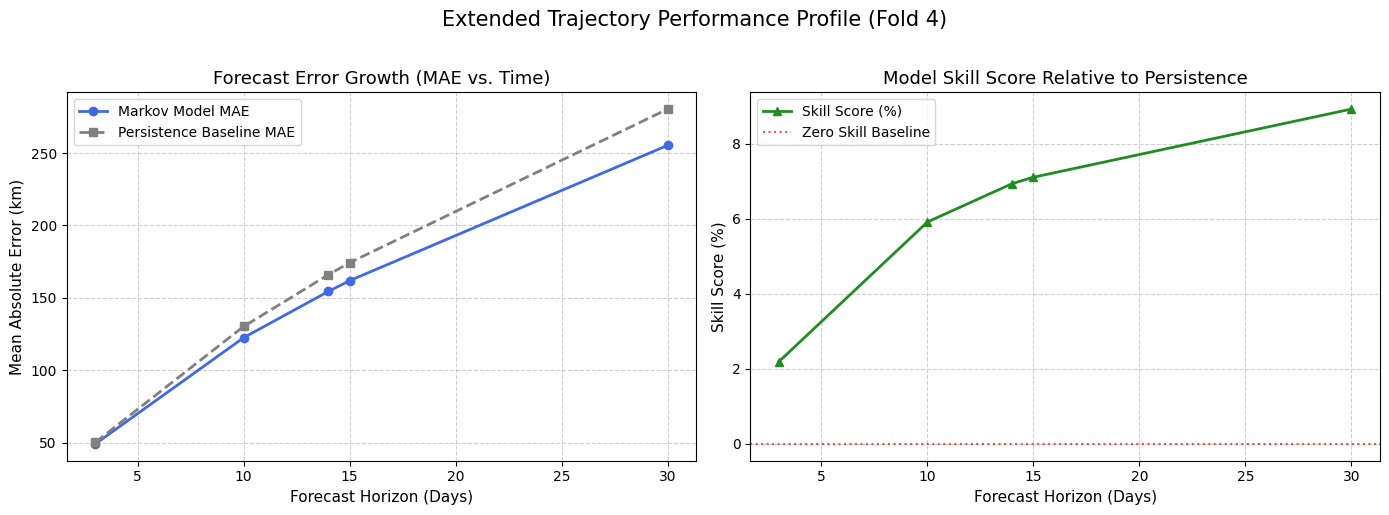

In [ ]:
# ==================================================================
# EXTENDED HORIZON EVALUATION ON BEST FOLD (Fold 4) & PLOTTING
# ==================================================================

# Extract the already-calculated 3-day, 10-day and 15-day results for Fold 4 (calculated earlier)
fold_4_base = cv_eval_summary[cv_eval_summary['Fold'] == 4].copy()

# Define new extended horizons in days (14 days and 30 days) and convert to 6-hour steps
target_days = [14, 30]
horizons_steps = [int(days * 24 / 6) for days in target_days]

# Get ONLY Fold 4 data from cv_results
fold_data = cv_results[3]   # Index 3 since Python uses 0-based indexing
fold = fold_data['fold']
P = fold_data['P']
visited = fold_data['visited']
df_test = fold_data['df_test']

print(f"Running Extended Horizons (14 & 30 Days) strictly for Fold {fold}...")

new_rows = []

# Loop only through the new extended steps for Fold 4
for days, n_steps in zip(target_days, horizons_steps):

    # Extract valid start/end trajectory pairs separated by the target horizon from the test set
    pr = build_pairs_xy(df_test, n_steps=n_steps)
    if len(pr) == 0:
        continue

    # Filter out start cells that were never seen/visited during training
    pr = pr[visited[pr['start'].values]].reset_index(drop=True)
    if len(pr) == 0:
        continue

    # Extract start state indices, starting LAT/LONG, and true ending LAT/LONG
    start = pr['start'].values
    lat0, lon0 = pr['lat0'].values, pr['lon0'].values
    lat1, lon1 = pr['lat1'].values, pr['lon1'].values

    # Find unique starting cells (to avoid redundant matrix power calculations)
    uniq, inv_ = np.unique(start, return_inverse=True)

    # Find forecasts (computes top-1 and expected mean for each unique start)
    top1, mean = forecast_points(P, uniq, n_steps, chunk_size=500, prune=1e-6)

    # Maps the unique predictions back to every individual evaluation pair using the inverse index (inv_)
    pred_lats = top1[inv_, 0]
    pred_lons = top1[inv_, 1]

    # Calculate Great-Circle distance errors (in km) for both our Markov model and the Persistence baseline
    d_model = hav(lat1, lon1, pred_lats, pred_lons)
    d_persist = hav(lat1, lon1, lat0, lon0)

    # Compute Mean Absolute Error (MAE) for markov and persistence baselines and
    # Skill Score percentage relative to persistence
    mean_model_mae = d_model.mean()
    mean_persist_mae = d_persist.mean()
    # Calculates the Skill Score percentage relative to persistence
    skill_pct = 100 * (1 - mean_model_mae / mean_persist_mae)

    # Record metrics for this fold and horizon into our summary results container
    new_rows.append({
        'Fold': fold,
        'Horizon_Days': days,
        'Eval_Pairs': len(pr),
        'Markov_MAE_km': mean_model_mae,
        'Persistence_MAE_km': mean_persist_mae,
        'Skill_vs_Persistence_%': skill_pct
    })

fold_4_new = pd.DataFrame(new_rows)

# Combine base (3 & 10 days) with new extended (14 & 30 days) for Fold 4
fold_4_extended = pd.concat([fold_4_base, fold_4_new]).sort_values('Horizon_Days').reset_index(drop=True)

# Display the complete table for Fold 4
display(fold_4_extended)

# ==================================================================
# Plotting MAE and Skill Score Curves
# ==================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: MAE Comparison (Markov vs. Persistence)
axes[0].plot(fold_4_extended['Horizon_Days'], fold_4_extended['Markov_MAE_km'], marker='o', color='royalblue', linewidth=2, label='Markov Model MAE')
axes[0].plot(fold_4_extended['Horizon_Days'], fold_4_extended['Persistence_MAE_km'], marker='s', color='gray', linestyle='--', linewidth=2, label='Persistence Baseline MAE')
axes[0].set_title('Forecast Error Growth (MAE vs. Time)', fontsize=13)
axes[0].set_xlabel('Forecast Horizon (Days)', fontsize=11)
axes[0].set_ylabel('Mean Absolute Error (km)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Plot 2: Skill Score Percentage Progression
axes[1].plot(fold_4_extended['Horizon_Days'], fold_4_extended['Skill_vs_Persistence_%'], marker='^', color='forestgreen', linewidth=2, label='Skill Score (%)')
axes[1].axhline(0, color='red', linestyle=':', alpha=0.7, label='Zero Skill Baseline')
axes[1].set_title('Model Skill Score Relative to Persistence', fontsize=13)
axes[1].set_xlabel('Forecast Horizon (Days)', fontsize=11)
axes[1].set_ylabel('Skill Score (%)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.suptitle(f"Extended Trajectory Performance Profile (Fold {fold})", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# ==================================================================
# STOCHASTIC ENERGY SCORE EVALUATION (Fold 4 - Markov VS Persistence)
# ==================================================================

# Generates a probability-weighted spatial distribution (Markov prediction cloud) from the transition matrix 'P_mat'
def simulate_garbage_trajectories(P_mat, start_states, n_steps=12, n_sims=500, rng=None):
    """
    Simulates stochastic particle trajectories forward in time for multiple starting cells simultaneously
    using Monte Carlo sampling over the Markov transition matrix.

    Parameters:
        P_mat (csr_matrix): The trained Markov transition probability matrix.
        start_states (array-like): List of starting grid cell state indices to simulate from.
        n_steps (default=12): Number of 6-hour time steps to simulate forward (e.g., 12 = 3 days).
        n_sims (default=500): Number of parallel stochastic particle simulation paths per starting cell.
        rng (np.random.Generator, optional): Random number generator for reproducible stochastic sampling.

    Returns:
        A tuple containing:
            - all_ends: 2D array of final ending states (shape: n_starts x n_sims)
    """
    # Initialize a default random number generator (rng)
    if rng is None:
        rng = np.random.default_rng(42)

    P_csr = P_mat.tocsr()  # Convert 'P_mat' to CSR format for fast sparse row-slicing

    n_starts = len(start_states)   # Total count of unique starting grid cells
    all_ends = np.empty((n_starts, n_sims), dtype=np.int64)   # 2D array to store final state for every simulation

    # Loop over each unique starting cell index
    for i, start_cell in enumerate(start_states):
        current_states = np.full(n_sims, start_cell, dtype=np.int64) # Initialize all sims with starting cell index

        # Looping through forecast timespans
        for _ in range(n_steps):
            next_states = np.empty_like(current_states)

            # Loop through each parallel simulation path
            for j in range(n_sims):
                s = current_states[j]

                # Look up sparse matrix index bounds for outgoing transitions
                row_start = P_csr.indptr[s]
                row_end = P_csr.indptr[s+1]

                if row_start == row_end:  # Absorbing/dead cell check
                    next_states[j] = s
                    continue

                neighbors = P_csr.indices[row_start:row_end]
                probs = P_csr.data[row_start:row_end]

                # Stochastically sample next state based on transition probabilities
                next_states[j] = rng.choice(neighbors, p=probs)

            current_states = next_states
        all_ends[i] = current_states

    return all_ends



# Evaluates the Markov model's probabilistic forecast accuracy against a static persistence baseline
# using Energy Scores
def evaluate_fold_4_energy_score(cv_results, horizons=[12, 40, 60], n_sims=500):
    """
    Evaluates probabilistic forecast performance for Fold 4 across specified forecast horizons
    by computing Energy Scores for both the Markov model and a static persistence baseline.

    Parameters:
        cv_results (list of dicts): Cross-validation results containing trained models, matrices, and test sets.
        horizons (default=[12, 40, 60]): Forecast step intervals (e.g., 12 = 3 days, 40 = 10 days).
        n_sims (default=500): Number of Monte Carlo simulation particles per start location.

    Returns:
        pd.DataFrame: A summary dataframe containing mean energy scores and skill scores vs. persistence.
    """

    summary_rows = []
    rng = np.random.default_rng(42) # Initialize reproducible random number generator (rng)

    # Get ONLY Fold 4 data from cv_results
    fold_data = cv_results[3]   # Index 3 since Python uses 0-based indexing
    fold = fold_data['fold']
    P = fold_data['P']
    visited = fold_data['visited']
    df_test = fold_data['df_test']

    print(f"Running Energy Score Evaluation strictly for Fold {fold}...")

    # Loop through every forecast timestep
    for n_steps in horizons:
        days = n_steps * 6 / 24 # Convert 'n_steps' to days

        # Extract valid start/end trajectory pairs separated by the target horizon from the test set
        pr = build_pairs_xy(df_test, n_steps=n_steps)
        if len(pr) == 0:
            continue

        # Filter out start cells that were never seen/visited during training
        pr = pr[visited[pr['start'].values]].reset_index(drop=True)
        if len(pr) == 0:
            continue

        # Subsample unique starting cells to a maximum of 500 if the list is too large
        unique_starts = pr['start'].unique()
        if len(unique_starts) > 500:
            unique_starts = rng.choice(unique_starts, 500, replace=False) #  Randomly pick a subset of 500

        # Run Monte Carlo simulation for a single batch
        ends = simulate_garbage_trajectories(P, unique_starts, n_steps=n_steps, n_sims=n_sims, rng=rng)
        sim_dict = {c: e for c, e in zip(unique_starts, ends)}  # Map start cell to its simulated particle cloud

        fold_es_model, fold_es_persist = [], []

        # Loop through every unique start cell and evaluate error metric for each
        for start_cell in unique_starts:
            subset_df = pr.loc[pr['start'] == start_cell]
            if len(subset_df) < 5:   # Sample size is too small to evaluate, thus gets skipped
                continue

            real_ends = subset_df['end'].values
            lat_r, lon_r = state_to_latlon(real_ends)

            # --- MODEL DISTRIBUTION (Markov Prediction Cloud) ---
            sim_ends = sim_dict[start_cell]
            u, cnts = np.unique(sim_ends, return_counts=True) # u --> unique end; cnt --> how many sims end in 'u'
            w = cnts / cnts.sum()   # Probability weights for each unique simulated end
            lat_u, lon_u = state_to_latlon(u)   # Convert simulated cloud states to LAT/LONG

            # Compute Energy Score components for the Markov Model (compare real ends to simulation cloud)
            e_xy = (hav(lat_r[:, None], lon_r[:, None], lat_u[None, :], lon_u[None, :]) * w).sum(axis=1)  # cross-term distance (reality)
            e_xx = w @ hav(lat_u[:, None], lon_u[:, None], lat_u[None, :], lon_u[None, :]) @ w  # internal spread (within simulated ends)
            es_m = e_xy.mean() - 0.5 * e_xx    # Final Energy Score for the Markov model

            # --- PERSISTENCE BASELINE (Static position assumption) ---
            lat0_arr, lon0_arr = subset_df['lat0'].values, subset_df['lon0'].values

            # Compute Energy Score components for Persistence
            # (Using a small jitter/spread around start or evaluating directly against start coordinates)
            e_px = hav(lat_r[:, None], lon_r[:, None], lat0_arr[None, :], lon0_arr[:, None]).mean(axis=1)
            e_pp = hav(lat0_arr[:, None], lon0_arr[:, None], lat0_arr[None, :], lon0_arr[:, None]).mean()
            es_p = e_px.mean() - 0.5 * e_pp   # Final Energy Score for the persistence baseline

            fold_es_model.append(es_m)
            fold_es_persist.append(es_p)

        # Aggregate and compute final skill metrics
        if len(fold_es_model) > 0:
            mean_m = np.mean(fold_es_model)
            mean_p = np.mean(fold_es_persist)
            skill_pct = 100 * (1 - mean_m / mean_p) if mean_p != 0 else 0.0

            summary_rows.append({
                'Fold': fold,
                'Forecast_Days': days,
                'Mean_Energy_Score_Model': mean_m,
                'Mean_Energy_Score_Persistence': mean_p,
                'Skill_vs_Persistence_%': skill_pct
            })

    # Return summary of energy scores
    return pd.DataFrame(summary_rows)


# Run and display Fold 4 Energy Score table
fold_4_energy_summary = evaluate_fold_4_energy_score(cv_results, horizons=[12, 40, 60])
print(fold_4_energy_summary.to_string(index=False))

Running Energy Score Evaluation strictly for Fold 4...
 Fold  Forecast_Days  Mean_Energy_Score_Model  Mean_Energy_Score_Persistence  Skill_vs_Persistence_%
    4            3.0                36.297276                      48.969854               25.878324
    4           10.0               100.893058                     135.845023               25.729294
    4           15.0               131.156914                     178.419519               26.489593


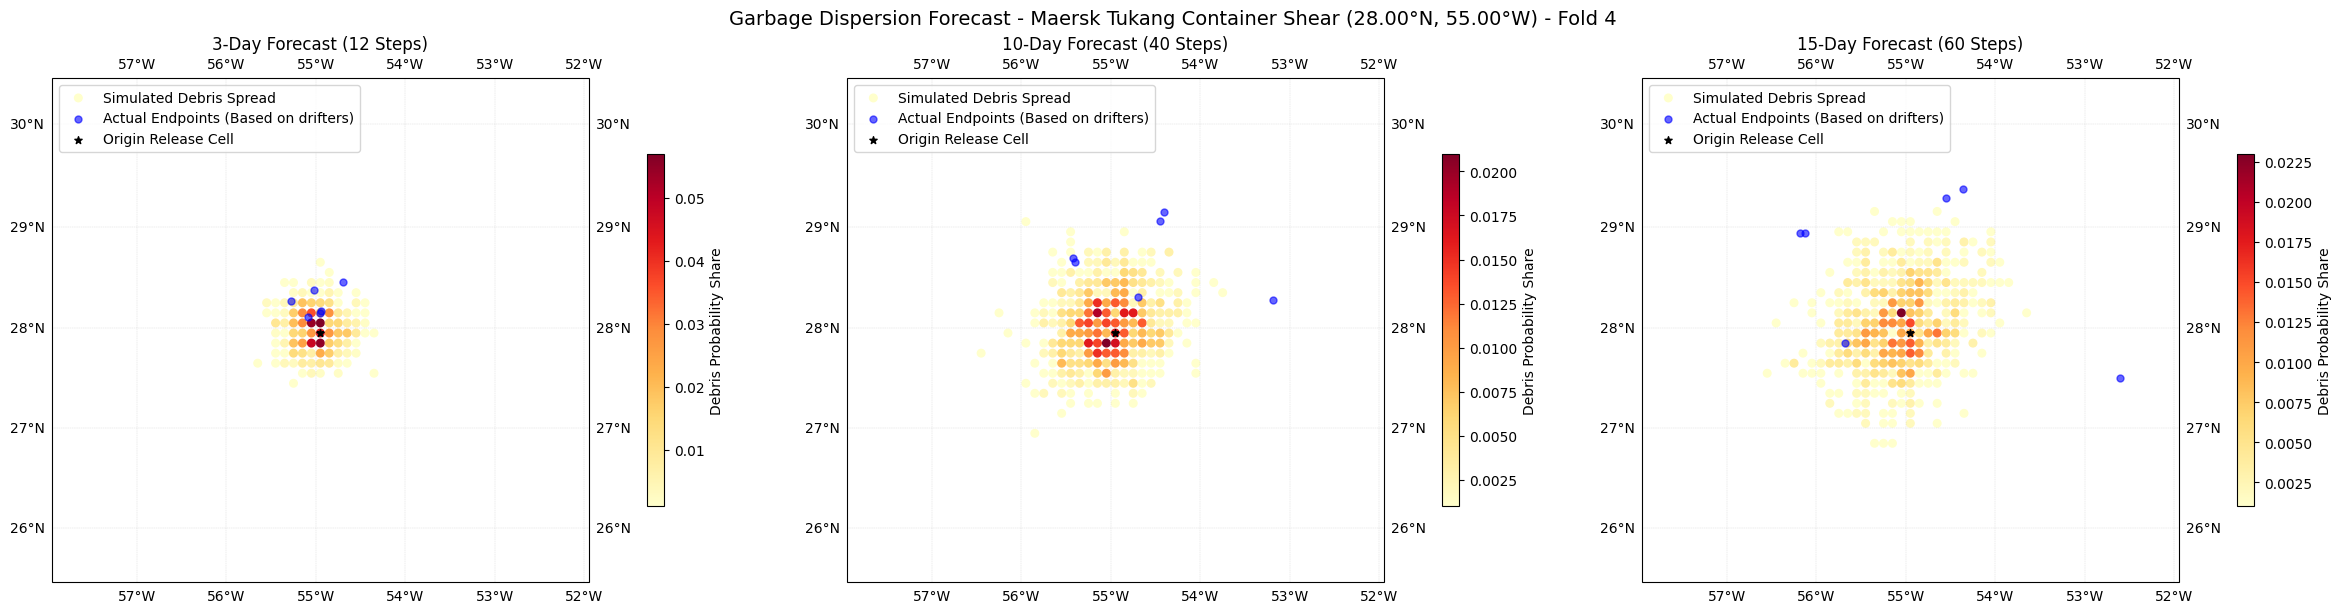

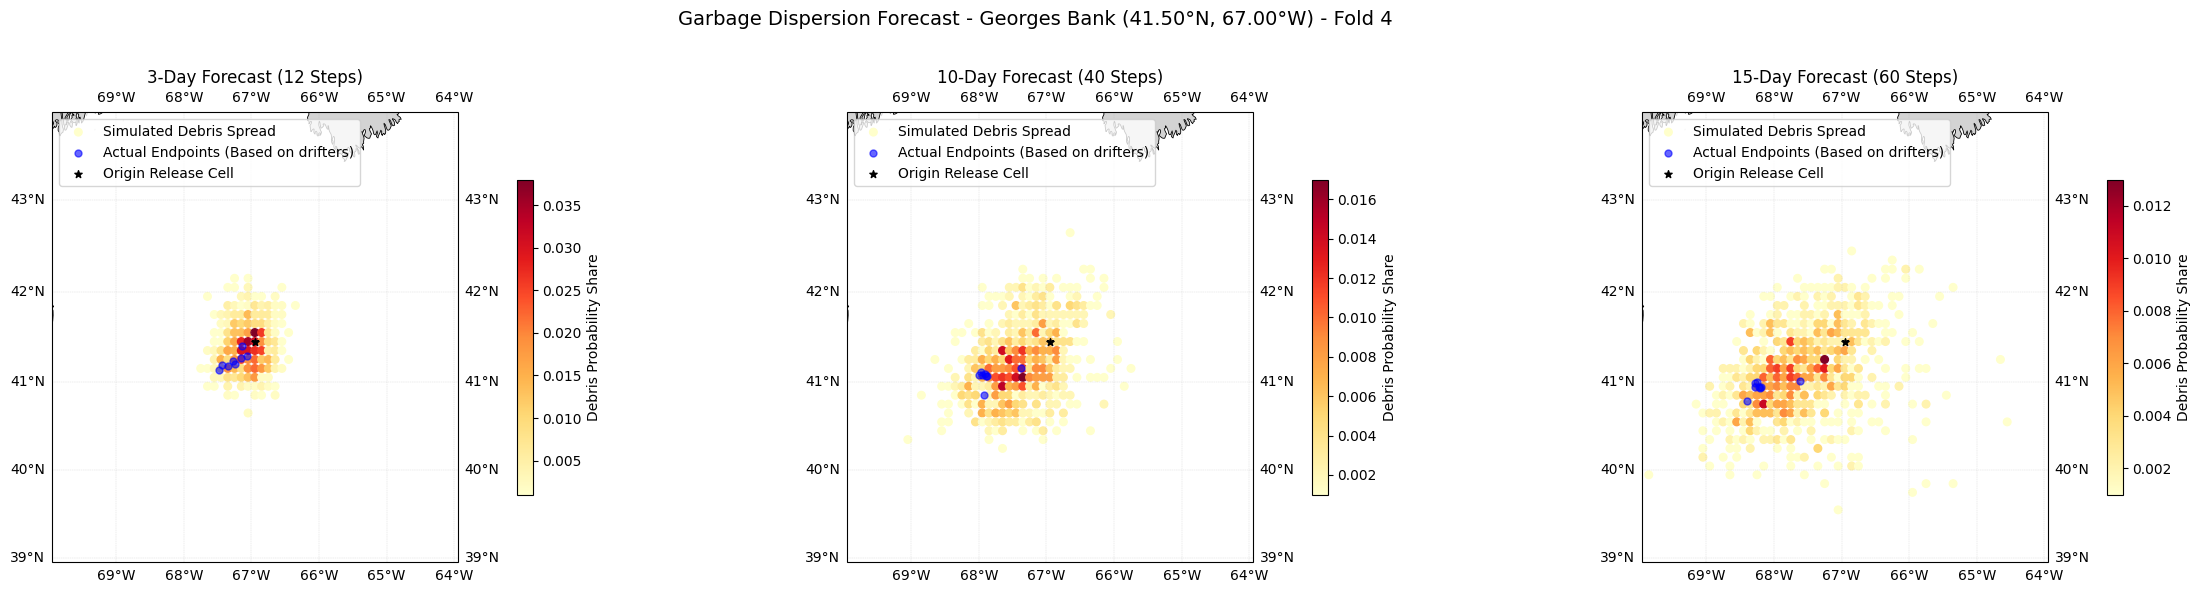

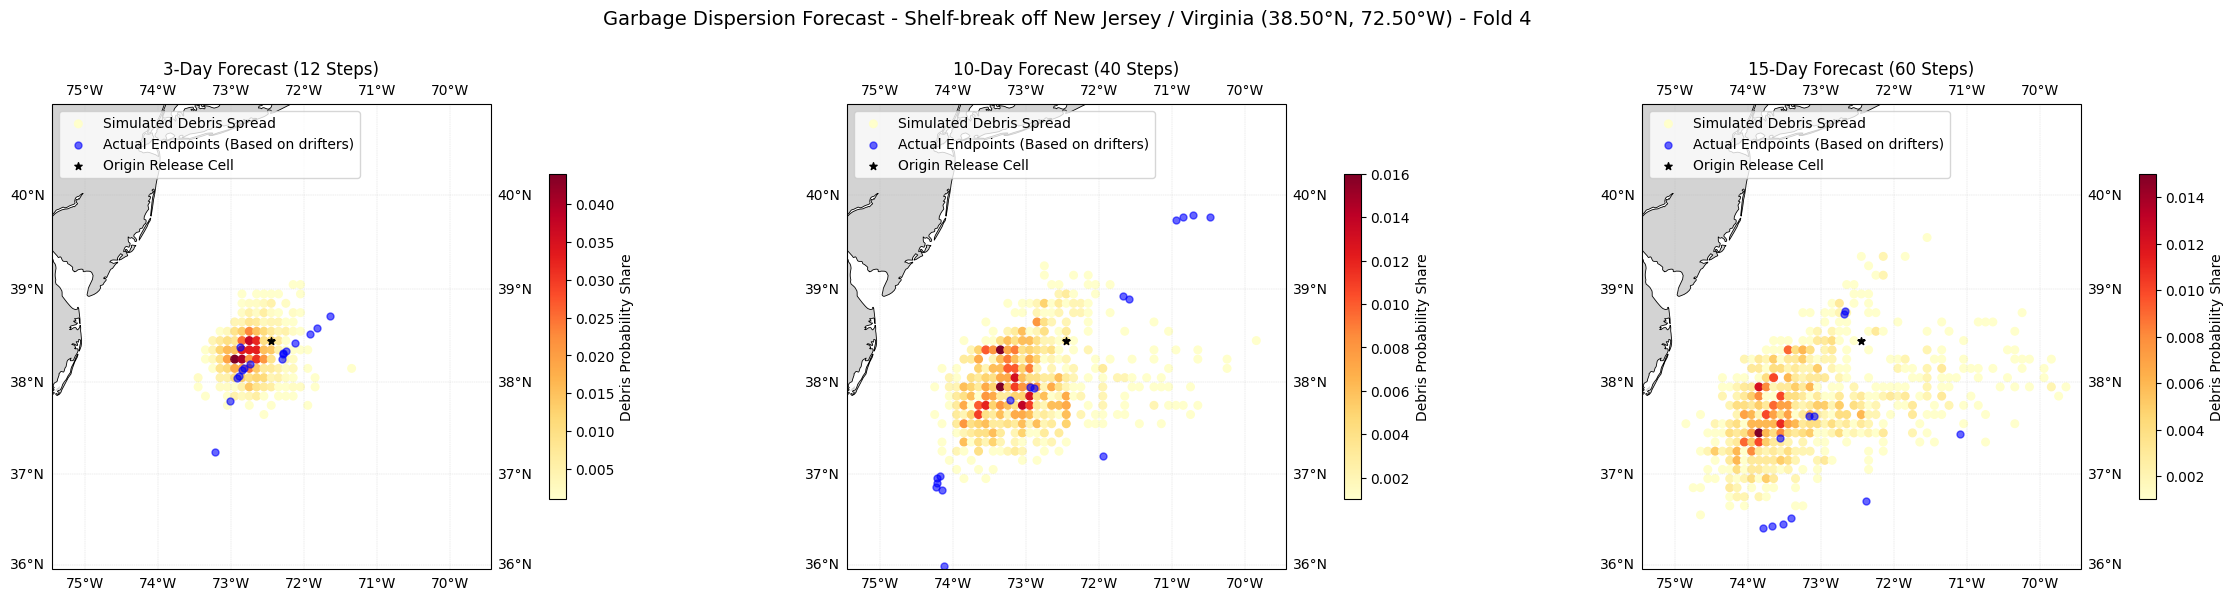

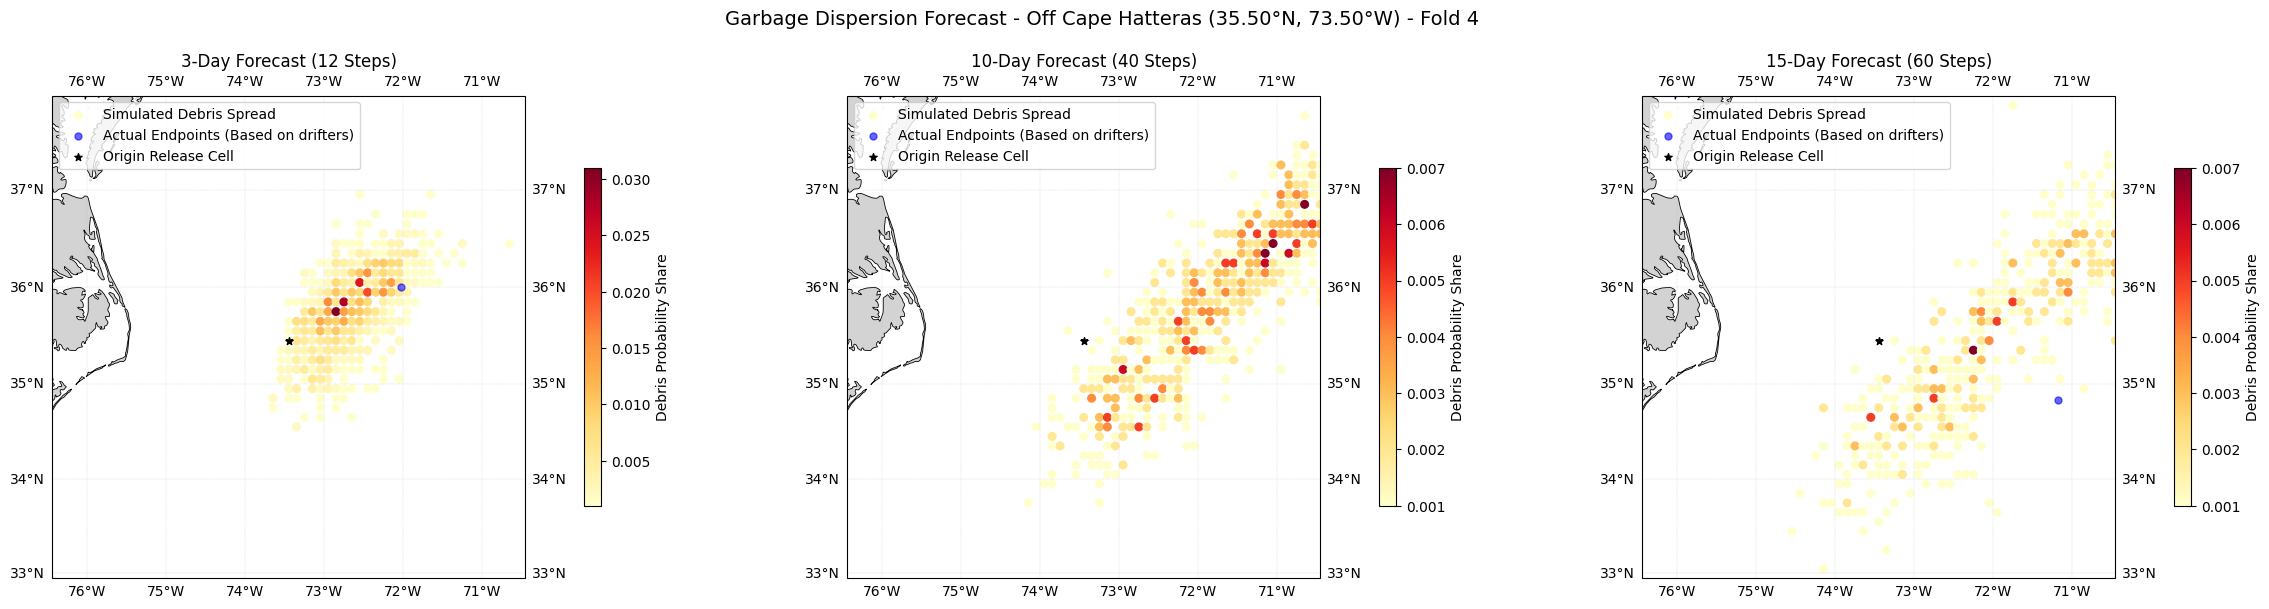

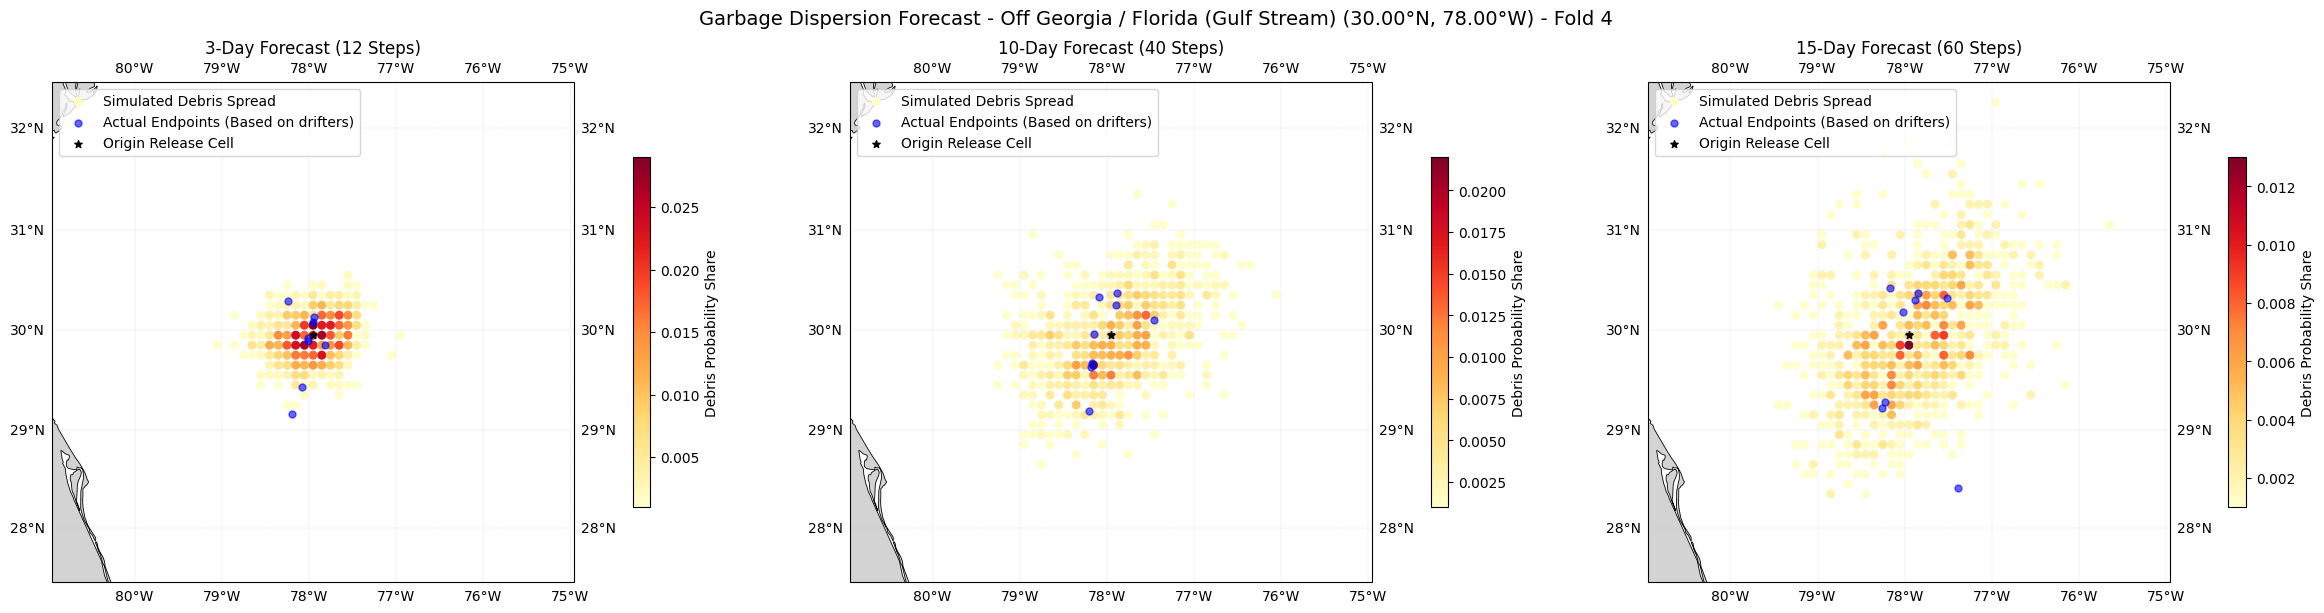

In [ ]:
# ==================================================================
# SINGLE-CELL VISUAL DISPERSION MAP FORECASTER
# ==================================================================

# Simulates and plots a spatial dispersion forecast from a single origin coordinate across multiple time horizons
def forecast_garbage_patch_fate(lat, lon, fold_idx=3, n_sims=1000, place=None):
    """
    Simulates and visualize probabilistic debris dispersion
    from any coordinate, for any fold index, across 3-day, 10-day and 15-day windows.

    Parameters:
        lat: Latitude coordinate of the release origin point.
        lon: Longitude coordinate of the release origin point.
        fold_idx (default=3): Index of the cross-validation fold to pull the transition matrix from (3 = Fold 4).
        n_sims (default=1000): Number of Monte Carlo simulation particles to run per horizon.
    """

    # Convert input LAT/LONG into grid and then back to LAT/LONG to get central LAT/LONG of the grid
    cell = int(to_state([lat], [lon])[0])
    latA, lonA = state_to_latlon(cell)

    # Extract the Markov Matrix and held-out test data of the required fold
    P = cv_results[fold_idx]['P']
    fold_num = cv_results[fold_idx]['fold']
    fold_df_test = cv_results[fold_idx]['df_test']   # this fold's own held-out drifters

    rng = np.random.default_rng(42) # Initialize reproducible random number generator (rng)

    # One panel per horizon
    horizons = [(12, "3-Day Forecast (12 Steps)"), (40, "10-Day Forecast (40 Steps)"), (60, "15-Day Forecast (60 Steps)")]

    # Initialize a side-by-side geographic subplot figure (one axis per horizon)
    fig, axes = plt.subplots(1, len(horizons), figsize=(8 * len(horizons), 6), subplot_kw={'projection': ccrs.Mercator()})
    sc = None   # To hold the scatter handle for the colorbar

    # Loop through each forecast horizon panel
    for ax, (n_steps, title_label) in zip(axes, horizons):
        # Run Monte Carlo simulation forward in time for the start cell
        ends = simulate_garbage_trajectories(P, [cell], n_steps=n_steps, n_sims=n_sims, rng=rng)
        sim_ends = ends[0]  # Extract simulated particle ends for this start cell

        # Calculate unique destination states and their particle frequency counts
        u, cnts = np.unique(sim_ends, return_counts=True)
        lat_u, lon_u = state_to_latlon(u)

        # Extract actual test endpoints for this horizon (from this fold's held-out drifters)
        pr = build_pairs_xy(fold_df_test, n_steps=n_steps)
        actual_subset = pr[pr['start'] == cell]
        if len(actual_subset) > 0:
            lat_actual, lon_actual = actual_subset['lat1'].values, actual_subset['lon1'].values
        else:
            lat_actual, lon_actual = [], []

        ax.set_extent([lonA - 3, lonA + 3, latA - 2.5, latA + 2.5], crs=ccrs.PlateCarree())

        # Plot simulation spread
        sc = ax.scatter(
            lon_u, lat_u, c=cnts/cnts.sum(), s=30, cmap='YlOrRd',
            transform=ccrs.PlateCarree(), label='Simulated Debris Spread'
        )

        # Plot actual recorded test end points
        if len(lat_actual) > 0:
            ax.scatter(
                lon_actual, lat_actual, marker='o', c='blue', s=25, alpha=0.6, transform=ccrs.PlateCarree(),
                label='Actual Endpoints (Based on drifters)'
            )

        # Plot the starting cell
        ax.scatter(lonA, latA, marker='*', c='black', s=30, transform=ccrs.PlateCarree(), label='Origin Release Cell')

        # Add geographic map features
        ax.add_feature(cfeature.LAND, facecolor='lightgray')
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5, linestyle='--')

        ax.set_title(title_label, fontsize=12)
        plt.colorbar(sc, ax=ax, shrink=0.7, pad=0.08, label='Debris Probability Share')
        ax.legend(loc='upper left')

    place_txt = f"{place} " if place else ""
    plt.suptitle(f"Garbage Dispersion Forecast - {place_txt}({lat:.2f}°N, {abs(lon):.2f}°W) - Fold {cv_results[fold_idx]['fold']}\n",
             fontsize=14)

    plt.tight_layout()
    plt.show()

# Run visual dispersion map using Fold 4 (Index 3 in Python)
forecast_garbage_patch_fate(lat=28.0, lon=-55.0, fold_idx=3, place="Maersk Tukang Container Shear")
forecast_garbage_patch_fate(lat=41.5, lon=-67.0, fold_idx=3, place="Georges Bank") # one of the richest fishing grounds
forecast_garbage_patch_fate(lat=38.5, lon=-72.5, fold_idx=3, place="Shelf-break off New Jersey / Virginia") # coastal water interacts with gulf stream
forecast_garbage_patch_fate(lat=35.5, lon=-73.5, fold_idx=3, place="Off Cape Hatteras") # diverse marine life
forecast_garbage_patch_fate(lat=30.0, lon=-78.0, fold_idx=3, place="Off Georgia / Florida (Gulf Stream)") # gulf stream
